In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## 1. Introduction

This lab focuses on analyzing the Telco Customer Churn dataset using Python in Kaggle Notebook. The analysis involves loading the dataset, inspecting its structure, preprocessing the data, and exploring the relationships between customer churn and different demographic, service, and payment attributes. The main objective is to understand the characteristics associated with customer churn and identify patterns that may help the telecommunications company improve customer retention.


In [1]:
import pandas as pd
from pathlib import Path

# Find the dataset attached to the Kaggle notebook
data_files = list(Path("/kaggle/input").rglob("*.csv"))

# Select the Telco Customer Churn dataset
matching_files = [
    file for file in data_files
    if "wa_fn-usec" in file.name.lower()
    and "telco-customer-churn" in file.name.lower()
]

if not matching_files:
    raise FileNotFoundError(
        "Dataset not found. Please add the Telco Customer Churn "
        "CSV file using Kaggle's Add Input option."
    )

file_path = matching_files[0]

# Load the dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset location:", file_path)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Dataset location: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Number of rows: 7043
Number of columns: 21


### Interpretation

The pandas library is imported to support data manipulation and analysis. The notebook searches the Kaggle input directory for the required Telco Customer Churn CSV file and loads it into a DataFrame named `df`. A DataFrame organizes data into rows and columns, making it suitable for analysis. The output displays the dataset location, number of records, and number of attributes. The dataset is now available for inspection and preprocessing.


In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Interpretation

The `head()` function displays the first five rows of the dataset by default. These rows provide an initial view of the available attributes, their column names, and the format of the recorded customer information. This inspection helps identify the variables that will be used in subsequent preprocessing and exploratory data analysis.


In [3]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


### Interpretation

The `tail()` function displays the last five rows of the dataset by default. It allows us to inspect records at the end of the file and confirm that the dataset contains customer information through its final rows. Together, the head and tail functions provide an initial overview of the dataset's contents.


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
Rows: 7043
Columns: 21


### Interpretation

This step displays all column names and the dimensions of the dataset. Examining the column names helps identify the attributes available for analysis, including customer demographics, services, contract information, payment methods, and the churn target. The dimensions show the number of customer records and attributes currently loaded.


In [5]:
print("Data types before preprocessing:")
print(df.dtypes)

Data types before preprocessing:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


### Interpretation

The `dtypes` attribute displays the original data type of every column. Numeric attributes may be stored as integers or floating-point numbers, while categorical attributes are generally stored as objects or strings. Inspecting these types helps identify columns that need conversion before further analysis. For example, TotalCharges may initially be stored as text even though it represents a numerical amount.


In [6]:
# Count missing values in each column
missing_before = df.isnull().sum()

print("Missing values in each attribute:")
print(missing_before[missing_before > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each attribute:
Series([], dtype: int64)

Total missing values: 0


### Interpretation

The `isnull()` function identifies missing values, and `sum()` counts them in each column. Displaying only columns with missing values makes it easier to identify attributes that may require cleaning. However, some missing values may be represented as blank strings rather than actual null values. Therefore, additional inspection is needed before deciding which records to remove.


In [7]:
# Convert TotalCharges to numeric
# Invalid or blank entries become NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)
print(
    "Missing TotalCharges values:",
    df["TotalCharges"].isnull().sum()
)

TotalCharges data type: float64
Missing TotalCharges values: 11


### Interpretation

The `TotalCharges` attribute represents the total amount charged to a customer and should be numeric. The `pd.to_numeric()` function converts valid values into a numerical data type. The argument `errors="coerce"` converts invalid or blank entries into missing values represented by NaN. This allows the missing values to be detected and handled correctly during preprocessing.


In [8]:
# Convert Churn from Yes/No to 1/0
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
}).astype("int64")

print("Churn values after conversion:")
print(df["Churn"].value_counts().sort_index())

print("\nChurn data type:", df["Churn"].dtype)

Churn values after conversion:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn data type: int64


### Interpretation

The Churn attribute is converted from categorical text into a binary numerical variable. A value of 1 represents a customer who churned, while a value of 0 represents a customer who did not churn. The value counts show the number of customers in each category, and the data type confirms that Churn is stored as an integer. This representation makes the churn variable easier to use in numerical summaries and subsequent analysis.


In [9]:
print("Data types after the initial conversions:")
print(df.dtypes)

Data types after the initial conversions:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


### Interpretation

This output displays the data types after the initial conversions. The Churn attribute should now have an integer data type, while TotalCharges should have a numerical data type. Other attributes should retain types suitable for their contents. Categorical attributes, such as gender, Partner, Dependents, Contract, and PaymentMethod, can remain as text because their values represent categories rather than numerical measurements.


In [10]:
missing_values = df.isnull().sum()

print("Attributes containing missing values:")
print(missing_values[missing_values > 0])

print(
    "\nTotal missing values in the dataset:",
    df.isnull().sum().sum()
)

Attributes containing missing values:
TotalCharges    11
dtype: int64

Total missing values in the dataset: 11


### Interpretation

This step identifies the attributes containing missing values after numerical conversion. Converting TotalCharges first allows blank or invalid entries to be recognized as missing values. The displayed counts show which attributes require attention and how many missing values exist in total. These results are used to determine the effect of removing incomplete records.


In [11]:
rows_before = df.shape[0]

# Remove rows containing at least one missing value
df = df.dropna().copy()

rows_after = df.shape[0]
rows_removed = rows_before - rows_after

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_removed)
print("\nMissing values remaining:", df.isnull().sum().sum())

Rows before cleaning: 7043
Rows after cleaning: 7032
Rows removed: 11

Missing values remaining: 0


### Interpretation

The `dropna()` function removes rows containing at least one missing value. The output compares the number of records before and after cleaning and shows how many rows were removed. The final missing-value count verifies whether any null values remain. Removing incomplete records produces a cleaner dataset for further analysis, although it also reduces the number of available observations.


In [12]:
print("Final cleaned dataset dimensions:", df.shape)

print("\nRemaining missing values by attribute:")
print(df.isnull().sum())

print("\nFinal data types:")
print(df.dtypes)

Final cleaned dataset dimensions: (7032, 21)

Remaining missing values by attribute:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Final data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
C

### Interpretation

This final verification displays the dimensions, remaining missing values, and data types of the cleaned dataset. A missing-value count of zero across all attributes confirms that no null values remain. The output also confirms that Churn is numerical and TotalCharges has an appropriate numerical type. The cleaned dataset is now ready for exploratory data analysis.


Gender distribution against churn:


,No Churn,Churn
gender,,
Female,2544,939
Male,2619,930



Churn percentage by gender:


,No Churn (%),Churn (%)
gender,,
Female,73.04,26.96
Male,73.80,26.20


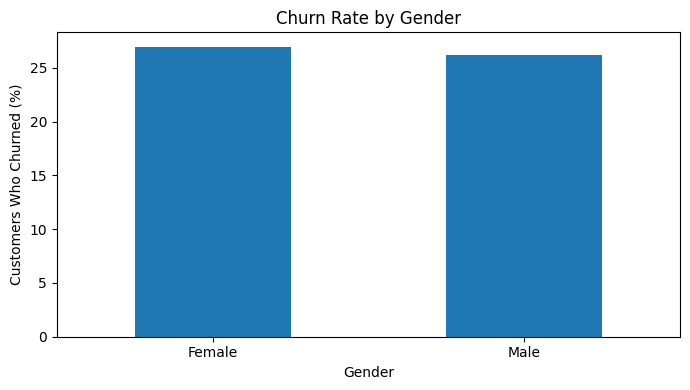

In [13]:
import matplotlib.pyplot as plt

gender_counts = pd.crosstab(
    df["gender"],
    df["Churn"]
).reindex(columns=[0, 1], fill_value=0)

gender_counts.columns = ["No Churn", "Churn"]

print("Gender distribution against churn:")
display(gender_counts)

gender_churn_rate = (
    pd.crosstab(df["gender"], df["Churn"], normalize="index")
    .reindex(columns=[0, 1], fill_value=0) * 100
)

gender_churn_rate.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by gender:")
display(gender_churn_rate.round(2))

gender_churn_rate["Churn (%)"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: Gender Distribution Against Churn

The frequency table compares the number of customers who churned and those who remained for each gender. The percentage table calculates the proportion of customers who churned within each gender group. Using percentages makes the comparison more meaningful when group sizes differ. The bar chart visualizes these churn percentages. The group with the higher percentage has a higher observed churn rate in this dataset. The results help determine whether churn differs noticeably by gender.


SeniorCitizen distribution against churn:


,No Churn,Churn
Non-Senior,4497,1393
Senior,666,476



Churn percentage by senior citizen status:


,No Churn (%),Churn (%)
Non-Senior,76.35,23.65
Senior,58.32,41.68


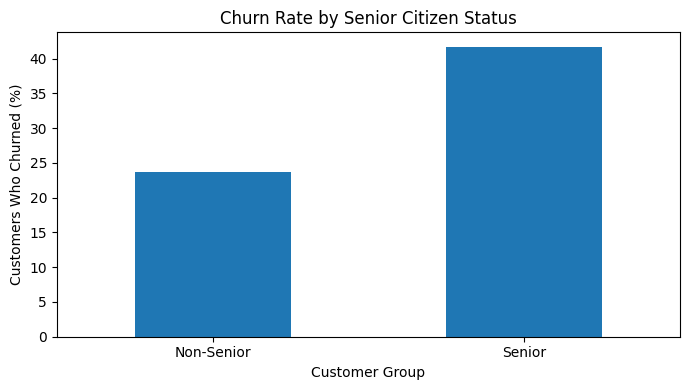

In [14]:
senior_counts = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

senior_counts.index = ["Non-Senior", "Senior"]
senior_counts.columns = ["No Churn", "Churn"]

print("SeniorCitizen distribution against churn:")
display(senior_counts)

senior_rates = (
    pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index")
    .reindex(index=[0, 1], columns=[0, 1], fill_value=0) * 100
)

senior_rates.index = ["Non-Senior", "Senior"]
senior_rates.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by senior citizen status:")
display(senior_rates.round(2))

senior_rates["Churn (%)"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Customer Group")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: SeniorCitizen and Churn

The analysis compares churn among senior citizens and non-senior citizens. In the original dataset, SeniorCitizen is coded as 0 for non-senior customers and 1 for senior customers. The frequency table shows the number of customers who churned or remained in each group, while the percentage table shows each group's churn rate. The bar chart makes the difference between the two groups easier to compare. The group with the higher churn percentage has a higher observed rate of customer loss.


Partner status against churn:


,No Churn,Churn
Partner,,
No,2439,1200
Yes,2724,669



Churn percentage by partner status:


,No Churn (%),Churn (%)
Partner,,
No,67.02,32.98
Yes,80.28,19.72


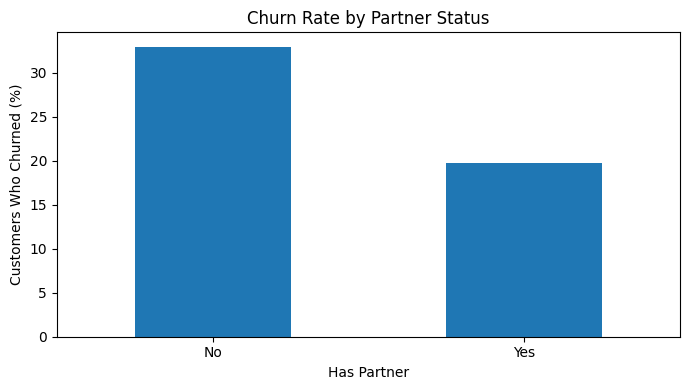

In [15]:
partner_counts = pd.crosstab(
    df["Partner"],
    df["Churn"]
).reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0)

partner_counts.columns = ["No Churn", "Churn"]

print("Partner status against churn:")
display(partner_counts)

partner_rates = (
    pd.crosstab(df["Partner"], df["Churn"], normalize="index")
    .reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0) * 100
)

partner_rates.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by partner status:")
display(partner_rates.round(2))

partner_rates["Churn (%)"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: Partner and Churn

This analysis investigates whether customer churn differs according to partner status. The table displays the numbers of customers who churned and those who remained among customers with and without partners. The churn percentages allow the two groups to be compared fairly. The bar chart provides a visual comparison of their churn rates. The group with the higher percentage experiences a higher observed proportion of churn, which may help the company understand differences between customer groups.


Dependents status against churn:


,No Churn,Churn
Dependents,,
No,3390,1543
Yes,1773,326



Churn percentage by dependents status:


,No Churn (%),Churn (%)
Dependents,,
No,68.72,31.28
Yes,84.47,15.53


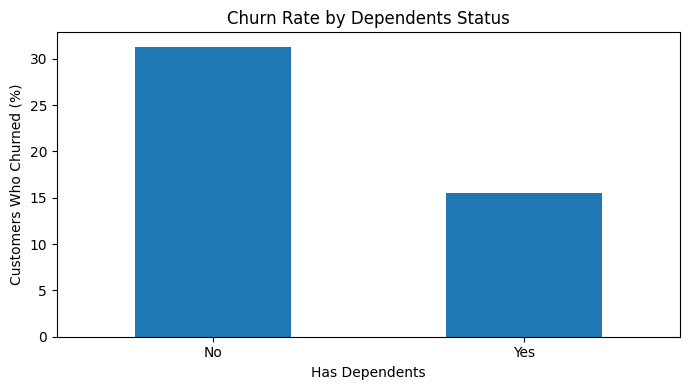

In [16]:
dependent_counts = pd.crosstab(
    df["Dependents"],
    df["Churn"]
).reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0)

dependent_counts.columns = ["No Churn", "Churn"]

print("Dependents status against churn:")
display(dependent_counts)

dependent_rates = (
    pd.crosstab(df["Dependents"], df["Churn"], normalize="index")
    .reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0) * 100
)

dependent_rates.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by dependents status:")
display(dependent_rates.round(2))

dependent_rates["Churn (%)"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Churn Rate by Dependents Status")
plt.xlabel("Has Dependents")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: Dependents and Churn

The analysis compares churn among customers who have dependents and those who do not. The frequency table displays the numbers of customers who churned and remained in each group. The percentage table calculates the churn rate within each group, allowing a fair comparison. The chart highlights any differences between the groups. The results indicate which group has a higher observed churn percentage and can help the company understand customer retention patterns.


PhoneService against churn:


,No Churn,Churn
PhoneService,,
No,510,170
Yes,4653,1699



Churn percentage by phone service:


,No Churn (%),Churn (%)
PhoneService,,
No,75.00,25.00
Yes,73.25,26.75


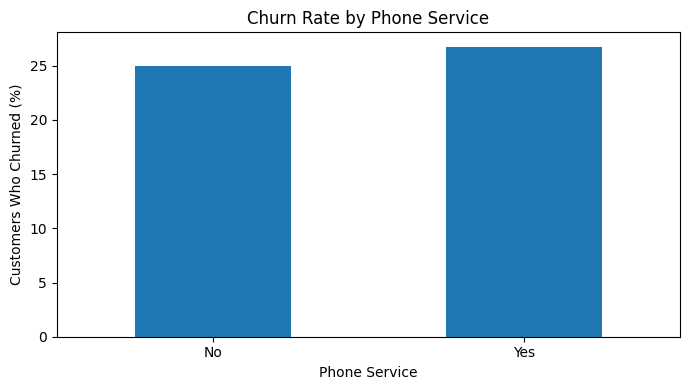

In [17]:
phone_counts = pd.crosstab(
    df["PhoneService"],
    df["Churn"]
).reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0)

phone_counts.columns = ["No Churn", "Churn"]

print("PhoneService against churn:")
display(phone_counts)

phone_rates = (
    pd.crosstab(df["PhoneService"], df["Churn"], normalize="index")
    .reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0) * 100
)

phone_rates.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by phone service:")
display(phone_rates.round(2))

phone_rates["Churn (%)"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Churn Rate by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: Phone Service Against Churn

This analysis examines the relationship between phone service availability and customer churn. The frequency table shows the number of customers who churned or remained among those with and without phone service. The percentage table compares churn rates within the two groups, and the bar chart visualizes these differences. The group with the higher churn percentage has a higher observed proportion of customers leaving. This comparison helps assess whether churn patterns differ according to phone service status.


Contract type against churn:


,No Churn,Churn
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48



Churn percentage by contract type:


,No Churn (%),Churn (%)
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


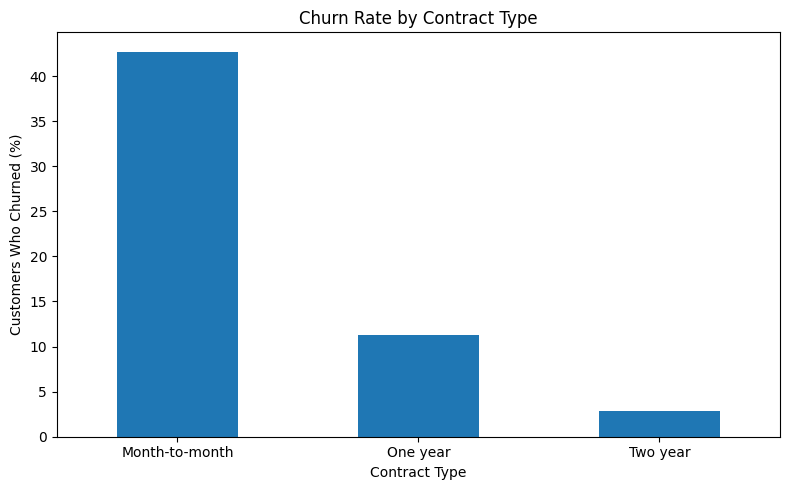

In [18]:
contract_counts = pd.crosstab(
    df["Contract"],
    df["Churn"]
).reindex(columns=[0, 1], fill_value=0)

contract_counts.columns = ["No Churn", "Churn"]

print("Contract type against churn:")
display(contract_counts)

contract_rates = (
    pd.crosstab(df["Contract"], df["Churn"], normalize="index")
    .reindex(columns=[0, 1], fill_value=0) * 100
)

contract_rates.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by contract type:")
display(contract_rates.round(2))

contract_rates["Churn (%)"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: Contract Type and Churn

The analysis compares customer churn across the available contract types. The frequency table shows how many customers churned and remained within each contract category. The percentage table calculates the churn rate for each type of contract, and the chart displays these rates for comparison. Differences between contract groups may indicate that contract arrangements are associated with different customer retention patterns. The group with the highest churn percentage has the greatest observed churn rate among the contract categories.


PaperlessBilling against churn:


,No Churn,Churn
PaperlessBilling,,
No,2395,469
Yes,2768,1400



Churn percentage by paperless billing:


,No Churn (%),Churn (%)
PaperlessBilling,,
No,83.62,16.38
Yes,66.41,33.59


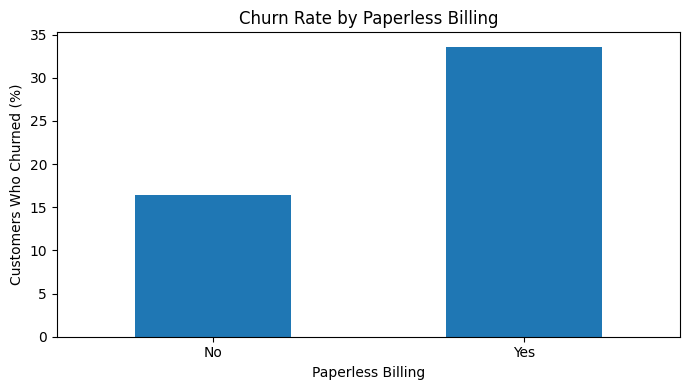

In [19]:
billing_counts = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"]
).reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0)

billing_counts.columns = ["No Churn", "Churn"]

print("PaperlessBilling against churn:")
display(billing_counts)

billing_rates = (
    pd.crosstab(df["PaperlessBilling"], df["Churn"], normalize="index")
    .reindex(index=["No", "Yes"], columns=[0, 1], fill_value=0) * 100
)

billing_rates.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by paperless billing:")
display(billing_rates.round(2))

billing_rates["Churn (%)"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: Paperless Billing and Churn

This analysis investigates whether churn differs between customers who use paperless billing and those who do not. The frequency table displays the number of customers who churned or remained in each group. The percentage table calculates each group's churn rate, while the chart makes the comparison easier to interpret. A higher percentage indicates a higher observed churn rate in that billing group. The results may help the company understand whether billing preferences are associated with customer retention.


Payment method against churn:


,No Churn,Churn
PaymentMethod,,
Bank transfer (automatic),1284,258
Credit card (automatic),1289,232
Electronic check,1294,1071
Mailed check,1296,308



Churn percentage by payment method:


,No Churn (%),Churn (%)
PaymentMethod,,
Bank transfer (automatic),83.27,16.73
Credit card (automatic),84.75,15.25
Electronic check,54.71,45.29
Mailed check,80.80,19.20


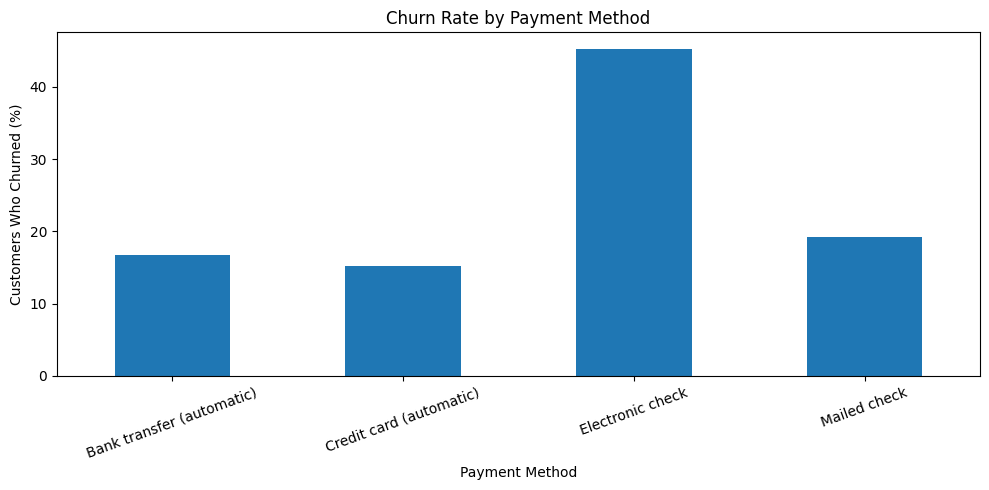

In [20]:
payment_counts = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
).reindex(columns=[0, 1], fill_value=0)

payment_counts.columns = ["No Churn", "Churn"]

print("Payment method against churn:")
display(payment_counts)

payment_rates = (
    pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index")
    .reindex(columns=[0, 1], fill_value=0) * 100
)

payment_rates.columns = ["No Churn (%)", "Churn (%)"]

print("\nChurn percentage by payment method:")
display(payment_rates.round(2))

payment_rates["Churn (%)"].plot(
    kind="bar",
    figsize=(10, 5),
    rot=20
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Customers Who Churned (%)")
plt.tight_layout()
plt.show()

### Interpretation: Payment Method and Churn

The analysis compares churn across the available payment methods. The frequency table displays the number of customers who churned and remained within each payment category. The percentage table calculates the churn rate for each payment method, allowing comparisons that account for differences in group sizes. The bar chart presents these churn rates visually. The payment category with the highest churn percentage has the highest observed churn rate in this dataset. These results may help the company identify payment-related patterns associated with customer retention.


## Conclusion

This lab used Python and pandas in a Kaggle Notebook to analyze the Telco Customer Churn dataset. The work included loading and inspecting the dataset, examining its data types, converting the Churn attribute into a numerical representation, identifying missing values, and removing incomplete records.

Exploratory data analysis was conducted to examine the relationships between customer churn and demographic characteristics, phone service, contract types, paperless billing, and payment methods. Frequency tables, churn percentages, and bar charts were used to compare customer groups and identify differences in their observed churn rates.

The results provide an overview of customer retention patterns in the dataset. These findings can help the telecommunications company identify customer groups that may require further investigation and develop more informed customer retention strategies. However, the observed relationships do not establish that any individual attribute directly causes customer churn.
